In [7]:
import numpy as np
import netCDF4 as nc
import xarray as xr
import os
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.lines as mlines
from matplotlib.colors import TwoSlopeNorm
import pandas as pd
import cartopy.crs as ccrs
# from ladcp_tools import *                  # load_all_stations, ...
# from tools import *                        # setup_map, load_satellite, load_eddies, plot_eddies
from tools_eg import *

In [8]:
EXTENT = None  # e.g. [10, 20, -42, -34]
lon_min, lon_max, lat_min, lat_max = 8, 25, -41, -34
extent = [lon_min, lon_max, lat_min, lat_max]

CRUISE_START = "2026-05-14"
CRUISE_END   = "2026-07-27"

ft = 10
# ADT colours: white exactly at 0, but each side stretched separately
# (ADT here is ~ -0.3 .. +1.5 m). Lower ADT_MIN -> darker cyclone blues,
# raise ADT_MAX -> fewer saturated anticyclone reds.
ADT_MIN, ADT_MAX = -0.3, 1.5
adt_norm = TwoSlopeNorm(vmin=ADT_MIN, vcenter=0, vmax=ADT_MAX)
levels = np.arange(ADT_MIN, ADT_MAX + 0.001, 0.02)
adt_ticks = [-0.3, 0, 0.3, 0.6, 0.9, 1.2, 1.5]

crs = ccrs.PlateCarree()
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max) / 2)


BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",   # full cruise (README)
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_LADCP = BASE / "data/LADCP/traitement_avec_SADCP"
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"
DIR_TRACKS = BASE / "figures/eddy_tracks"
DIR_CODE = BASE / "analysis"          # where ladcp_tools.py lives

DIR_DRIFTERS =  BASE / "data/DRIFTERS/drifters"
DIR_GEOJSON = BASE / "data/DRIFTERS/drifters_tracks.geojson"

DIR_MVP = BASE / "data/MVP_Data_processed"

# Animation
ANIM_START = "2026-07-01"                 # first drifter deployment
ANIM_END   = CRUISE_END                   # days without an ADT file are skipped
TAIL_DAYS  = 5                            # length of the track drawn behind each drifter (None = whole track)

# Drifter data: "csv" (folder of CSV snapshots, DIR_DRIFTERS) or "geojson" (DIR_GEOJSON)
DRIFTER_SOURCE = "csv"
FIRST_LAUNCH = "2026-07-01 05:00"         # fixes before this are bench tests (as in Solange's script)
FRAME_DIR = "whirls_drifters_animation"
OUT_MP4   = "whirls_drifters_animation.mp4"
FPS = 2                                   # frames (days) per second

os.makedirs(FRAME_DIR, exist_ok=True)

In [9]:
# ----------------------------------------------------------------------------
# Things loaded ONCE (they don't change from day to day)
# ----------------------------------------------------------------------------
# Bathymetry
bathymetry_data = xr.open_dataset(FNAME_BATHY)
lon_subset = bathymetry_data["lon"].sel(lon=slice(lon_min, lon_max))
lat_subset = bathymetry_data["lat"].sel(lat=slice(lat_min, lat_max))
depth_subset = bathymetry_data["topo"].sel(lon=slice(lon_min, lon_max),
                                           lat=slice(lat_min, lat_max))

# File lists
daily_ssh_files = sorted(os.listdir(DIR_SSH))
eddy_files_better = sorted(os.listdir(DIR_EDDIES['TOEDDIES_better_ADT']))
eddy_files_std = sorted(os.listdir(DIR_EDDIES['TOEDDIES']))

type_SADCP = "OS38"
sadcp = nc.Dataset(SADCP_FILES[type_SADCP])


In [30]:
transect = "Transect 12"
transect_path = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/MVP_Data_processed/{transect}/'
out_dir = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/mvp/{transect}/'
if not os.path.isdir(out_dir):
    os.mkdir(out_dir)

In [31]:
files = sorted(Path(transect_path).glob("*.csv"))
dfs = []
for k, f in enumerate(files):
    df = pd.read_csv(f)
    df["CAST"] = k          # one processed CSV file = one MVP cast
    dfs.append(df)
mvp_trans = pd.concat(dfs, ignore_index=True)
print(len(files), "files")

118 files


In [32]:
sadcp_all = {}
for inst in ["OS150", "OS38"]:
    s = cascade_add_time(xr.open_dataset(SADCP_FILES[inst]))
    s = s.sortby("time")
    s = s.isel(time=~s.indexes["time"].duplicated())
    sadcp_all[inst] = sadcp_for_transect(mvp_trans, s)

sadcp_tr  = sadcp_all["OS150"]          # used for positions (and in the cell below)
sadcp_mvp = sadcp_on_mvp_times(mvp_trans, sadcp_tr, max_gap="30min")

mvp_trans["LON (°E)"] = mvp_trans["LON (°E)"].fillna(pd.Series(sadcp_mvp["LONGITUDE"].values, index=mvp_trans.index))
mvp_trans["LAT (°N)"] = mvp_trans["LAT (°N)"].fillna(pd.Series(sadcp_mvp["LATITUDE"].values, index=mvp_trans.index))

print("MVP samples without position:", mvp_trans["LAT (°N)"].isna().sum(), "of", len(mvp_trans))

MVP samples without position: 0 of 494501


In [33]:
# OS150 above Z_SPLIT (150 m), OS38 below: sadcp_window keeps the right depths for each
a = sadcp_window("OS150", sadcp=cascade_to_window_format(sadcp_all["OS150"], pgood_min=50))
b = sadcp_window("OS38",  sadcp=cascade_to_window_format(sadcp_all["OS38"],  pgood_min=50))
print("OS150:", len(a["time"]), "profiles,", a["z"].min(), "-", a["z"].max(), "m")
print("OS38: ", len(b["time"]), "profiles,", b["z"].min(), "-", b["z"].max(), "m")

# put both on the same time axis (both are 10-min means), then stack in depth
t = np.union1d(a["time"], b["time"])
def on_t(d, key):
    out = np.full((len(t),) + d[key].shape[1:], np.nan)
    out[np.searchsorted(t, d["time"])] = d[key]
    return out

lon_a, lat_a = on_t(a, "lon"), on_t(a, "lat")
sadcp_mvp_processed = dict(
    time=t,
    lon=np.where(np.isnan(lon_a), on_t(b, "lon"), lon_a),
    lat=np.where(np.isnan(lat_a), on_t(b, "lat"), lat_a),
    z=np.concatenate([a["z"], b["z"]]),
    u=np.concatenate([on_t(a, "u"), on_t(b, "u")], axis=1),
    v=np.concatenate([on_t(a, "v"), on_t(b, "v")], axis=1))
print(len(sadcp_mvp_processed["time"]), "SADCP profiles,",
      sadcp_mvp_processed["z"].min(), "-", sadcp_mvp_processed["z"].max(), "m")

Calculating Mean
  ! PGOOD_ADCP is all 0 in this file -> PGOOD mask skipped
Calculating Mean
OS150: 146 profiles, 24.260000228881836 - 144.25999450683594 m
OS38:  146 profiles, 167.4600067138672 - 983.4600219726562 m
146 SADCP profiles, 24.260000228881836 - 983.4600219726562 m


In [34]:
# ---------------- map background for the combined figure ----------------
out_dir = str(BASE / "figures/mvp") + f"/{transect}/"

date = pd.to_datetime(mvp_trans["TIME"]).median().strftime("%Y-%m-%d")
date_compact = date.replace("-", "")
ssh = load_satellite(DIR_SSH / [f for f in daily_ssh_files if date in f or date_compact in f][0])
eddy_files, eddy_source = get_eddy_files(date_compact, date)

edds = eddies_on_transect(eddy_files, mvp_trans["LON (°E)"].values, mvp_trans["LAT (°N)"].values)
print("eddies crossed:", [("C" if e["cyc"] else "AC") + f" ({e['dist_km']:.0f} km from track)" for e in edds])


eddies crossed: ['C (15 km from track)', 'AC (58 km from track)']


118 casts used


/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/analysis/tools_eg.py:1160: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmap, shading="nearest",


  C: TOEddies center at -16 km, outside section (-2-272 km) -> not marked
  C: Nencioli minimum on the edge of the search box -> no centre


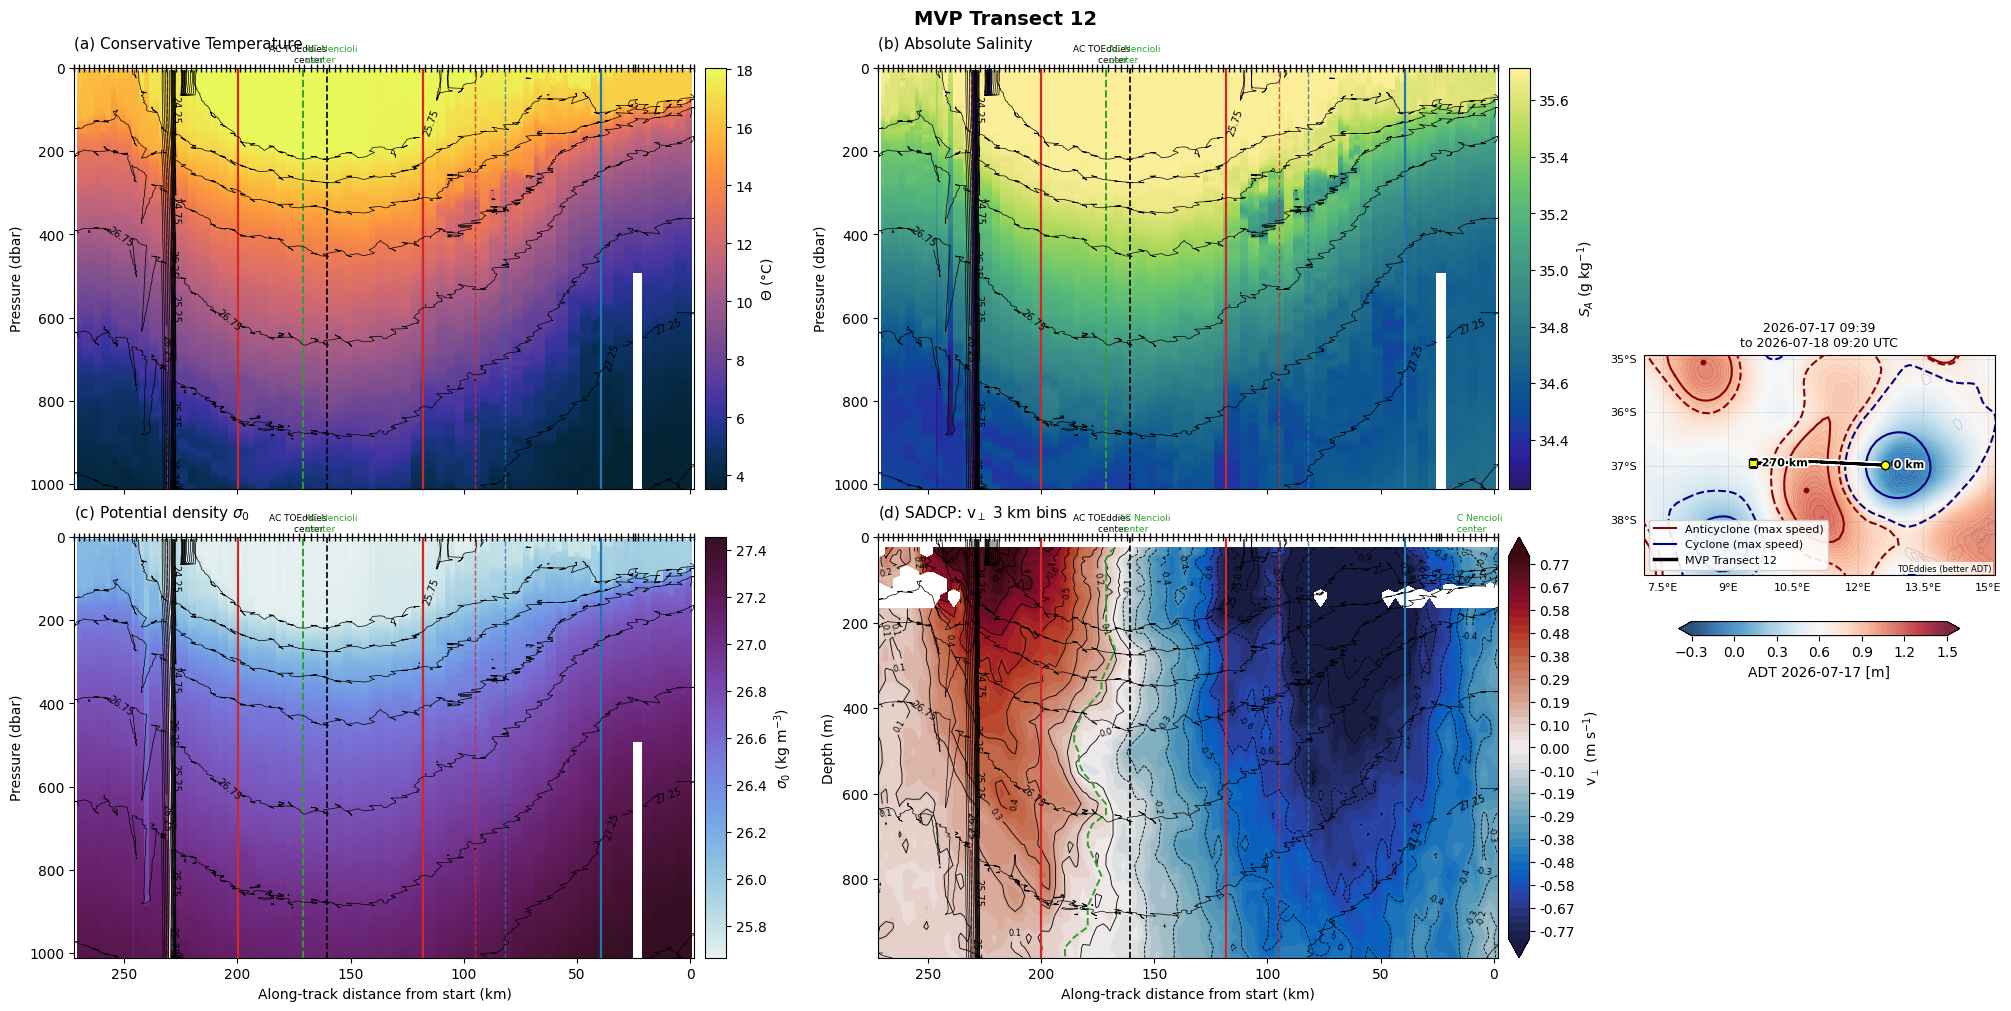

In [35]:
# ---------------- SADCP for zeta (PV) ----------------
ds = sadcp_tr                      # ADCP subset for this transect (sadcp_mvp is ~1 GB, not needed)
zdim = ds["depth"].dims[0]
u = ds["UVEL_ADCP_CORTIDE"].transpose("time", zdim).values
v = ds["VVEL_ADCP_CORTIDE"].transpose("time", zdim).values
pg = ds["PGOOD_ADCP"].transpose("time", zdim).values

u[pg < 50] = np.nan
v[pg < 50] = np.nan

args = [ssh, eddy_files, transect, eddy_source, adt_ticks, date, levels]
invert_x = True

if transect == "Transect 13" or transect == "Transect 14":
    sadcp_mvp_processed["u"] = -sadcp_mvp_processed["u"]
    sadcp_mvp_processed["v"] = -sadcp_mvp_processed["v"]
    invert_x = False
# ---------------- map + Theta / S_A / sigma0 ----------------
sec, fig, axs = process_transect(
    mvp_trans, adcp=sadcp_mvp_processed, cast_col="CAST",
    map_draw=draw_background,      # map_extent=extent  -> whole region instead of zoom
    map_args = args,
    title=f"MVP {transect}",
    eddy=edds,
    savepath=out_dir + f"{transect}_sections_hydro_adcp",
    flip_x = invert_x,
    vel_lim = 0.8)
plt.show()

In [36]:
# ---------------- CTD background profile: casts outside every TOEddies contour ----------------
# Casts selected by whirls_ctd_outside_eddies.py (outside_eddies == True in the CSV).
import warnings
DIR_CTD = BASE / "data/CTD"
MD_CTD_NC = DIR_CTD / "ctd_metadata.nc"
CLASS_CSV = DIR_CTD / "ctd_toeddies_classification.csv"
PROFILE_EXT = (".nc", ".cnv", ".csv")   # preferred profile format first
REF_DP = 1.0                            # dbar, same bins as the MVP section
REF_MIN_N = 3                           # keep only pressure levels with >= this many casts

NAMES = {"p": ["prDM", "prdM", "prSM", "pr", "PRES", "pres", "pressure", "PRESSURE"],
         "t": ["t090C", "t068C", "t190C", "TEMP", "temp", "temperature", "TEMPERATURE"],
         "s": ["sal00", "sal11", "PSAL", "psal", "salinity", "SALINITY"]}
STD_NAMES = {"p": "sea_water_pressure", "t": "sea_water_temperature",
             "s": "sea_water_practical_salinity"}


def _txt(v):
    return v.decode().strip() if isinstance(v, bytes) else str(v).strip()


def find_profile_file(name):
    """Profile file of one cast under DIR_CTD, from the metadata 'file' entry."""
    stem = Path(name).stem
    hits = [f for f in DIR_CTD.rglob(f"{stem}*") if f.suffix.lower() in PROFILE_EXT
            and f.resolve() != MD_CTD_NC.resolve()]
    if not hits:
        return None
    hits.sort(key=lambda f: (PROFILE_EXT.index(f.suffix.lower()), f.stem != stem, len(f.name)))
    return hits[0]


def _pick(cols, key, std=None):
    for n in NAMES[key]:
        if n in cols:
            return n
    low = {c.lower(): c for c in cols}
    for n in NAMES[key]:
        if n.lower() in low:
            return low[n.lower()]
    return std


def read_cnv(path):
    names, rows, bad, in_data = [], [], -9.990e-29, False
    with open(path, errors="ignore") as f:
        for line in f:
            if in_data:
                parts = line.split()
                if len(parts) == len(names):
                    rows.append(parts)
            elif line.startswith("# name"):
                names.append(line.split("=", 1)[1].split(":")[0].strip())
            elif line.startswith("# bad_flag"):
                bad = float(line.split("=")[1])
            elif line.startswith("*END*"):
                in_data = True
    df = pd.DataFrame(np.asarray(rows, float), columns=names)
    return df.mask(np.isclose(df, bad))


def read_ctd_profile(path):
    """-> p (dbar), in-situ T, practical S of one cast (downcast only)."""
    suf = path.suffix.lower()
    if suf == ".nc":
        ds = xr.open_dataset(path)
        cols = list(ds.variables)
        by_std = {k: next((v for v in cols if ds[v].attrs.get("standard_name") == s), None)
                  for k, s in STD_NAMES.items()}
        names = {k: _pick(cols, k, by_std[k]) for k in "pts"}
        if None in names.values():
            raise KeyError(f"{path.name}: no pressure/temperature/salinity among {cols}")
        p, t, s = (np.asarray(ds[names[k]].values, float).squeeze() for k in "pts")
        ds.close()
    else:
        df = read_cnv(path) if suf == ".cnv" else pd.read_csv(path)
        names = {k: _pick(list(df.columns), k) for k in "pts"}
        if None in names.values():
            raise KeyError(f"{path.name}: no pressure/temperature/salinity among {list(df.columns)}")
        p, t, s = (df[names[k]].to_numpy(float) for k in "pts")
    if p.ndim != 1:
        raise ValueError(f"{path.name}: pressure is {p.ndim}-D, expected one profile per file")
    imax = int(np.nanargmax(p))                    # downcast: surface -> deepest point
    return p[:imax + 1], t[:imax + 1], s[:imax + 1], names


def bin_on_grid(p, val, p_edges):
    idx = np.digitize(p, p_edges) - 1
    ok = (idx >= 0) & (idx < len(p_edges) - 1) & np.isfinite(val)
    s = np.bincount(idx[ok], val[ok], minlength=len(p_edges) - 1)
    n = np.bincount(idx[ok], minlength=len(p_edges) - 1)
    with np.errstate(invalid="ignore"):
        return np.where(n > 0, s / n, np.nan)


# ---- casts used for the background ----
USE_ALL_CASTS = True          # False -> only the casts outside every TOEddies contour

cls = pd.read_csv(CLASS_CSV, parse_dates=["time"])
ref_casts = (cls if USE_ALL_CASTS else cls[cls["outside_eddies"]]).reset_index(drop=True)
md = xr.open_dataset(MD_CTD_NC)
md_file = [_txt(v) for v in np.asarray(md["file"].values).ravel()]
md_pmax = np.asarray(md["max_pressure"].values, float).ravel()
md.close()
print(f"{len(ref_casts)} casts used for the background "
      f"({'all casts' if USE_ALL_CASTS else 'outside every TOEddies contour'})")

p_edges = np.arange(0, np.nanmax(md_pmax) + REF_DP, REF_DP)
p_ref = 0.5 * (p_edges[1:] + p_edges[:-1])
CT_list, SA_list, used = [], [], []
for _, c in ref_casts.iterrows():
    path = find_profile_file(md_file[c["cast"]])
    if path is None:
        print(f"  ! station {c['station']}: no profile file for '{md_file[c['cast']]}' under {DIR_CTD}")
        continue
    p, t, sp, names = read_ctd_profile(path)
    SA = gsw.SA_from_SP(sp, p, c["lon"], c["lat"])
    CT = gsw.CT_from_t(SA, t, p)
    CT_list.append(bin_on_grid(p, CT, p_edges))
    SA_list.append(bin_on_grid(p, SA, p_edges))
    used.append(c)
    print(f"  station {c['station']:>4}: {path.name} ({names['p']}, {names['t']}, {names['s']}), "
          f"0-{np.nanmax(p):.0f} dbar")

CT_all, SA_all = np.array(CT_list), np.array(SA_list)
ref_used = pd.DataFrame(used).reset_index(drop=True)
n_ref = np.isfinite(CT_all).sum(axis=0)
keep = n_ref >= REF_MIN_N
with warnings.catch_warnings():                # levels without data -> NaN, no warning
    warnings.simplefilter("ignore", RuntimeWarning)
    CT_mean, SA_mean = np.nanmean(CT_all, axis=0), np.nanmean(SA_all, axis=0)
    CT_std, SA_std = np.nanstd(CT_all, axis=0), np.nanstd(SA_all, axis=0)
ctd_ref = dict(p=p_ref[keep], CT=CT_mean[keep], SA=SA_mean[keep],
               sig0=gsw.sigma0(SA_mean, CT_mean)[keep],
               CT_std=CT_std[keep], SA_std=SA_std[keep], n=n_ref[keep])
print(f"\nbackground from {len(ref_used)} casts, 0-{ctd_ref['p'].max():.0f} dbar "
      f"(levels with >= {REF_MIN_N} casts)")
print(f"sigma0 range of the background: {ctd_ref['sig0'].min():.3f} .. {ctd_ref['sig0'].max():.3f}")
print(f"lightest MVP sigma0 in this transect: {np.nanmin(sec['sig0']):.3f}")


105 casts used for the background (all casts)
  station    1: wh26st001_tps.cnv (prDM, t090C, sal00), 0-326 dbar
  station    2: wh26st002_tps.cnv (prDM, t090C, sal00), 0-1200 dbar
  station    3: wh26st003_tps.cnv (prDM, t090C, sal00), 0-4473 dbar
  station    4: wh26st004_tps.cnv (prDM, t090C, sal00), 0-202 dbar
  station    5: wh26st005_tps.cnv (prDM, t090C, sal00), 0-1201 dbar
  station    6: wh26st006_tps.cnv (prDM, t090C, sal00), 0-251 dbar
  station    7: wh26st007_tps.cnv (prDM, t090C, sal00), 0-1205 dbar
  station    8: wh26st008_tps.cnv (prDM, t090C, sal00), 0-302 dbar
  station    9: wh26st009_tps.cnv (prDM, t090C, sal00), 0-1202 dbar
  station   10: wh26st010_tps.cnv (prDM, t090C, sal00), 0-1203 dbar
  station   11: wh26st011_tps.cnv (prDM, t090C, sal00), 0-301 dbar
  station   12: wh26st012_tps.cnv (prDM, t090C, sal00), 0-1202 dbar
  station   13: wh26st013_tps.cnv (prDM, t090C, sal00), 0-1209 dbar
  station   14: wh26st014_tps.cnv (prDM, t090C, sal00), 0-1201 dbar
  stati

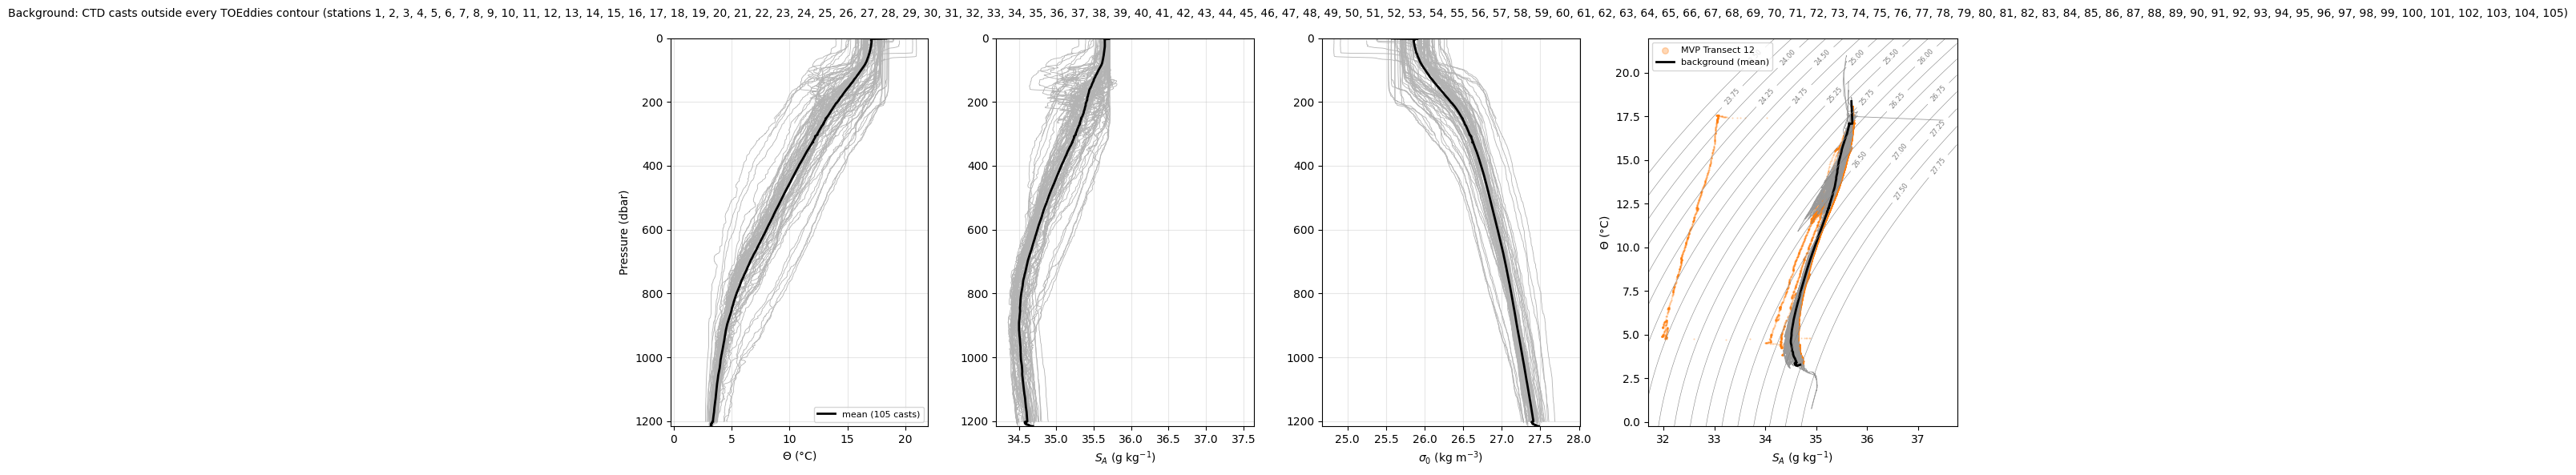

In [37]:
# ---------------- check the background profile ----------------
sig_ref_all = gsw.sigma0(SA_all, CT_all)
fig, ax = plt.subplots(1, 4, figsize=(17, 6), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.2]))
for a, data, mean, lab in [(ax[0], CT_all, ctd_ref["CT"], r"$\Theta$ (°C)"),
                           (ax[1], SA_all, ctd_ref["SA"], r"$S_A$ (g kg$^{-1}$)"),
                           (ax[2], sig_ref_all, ctd_ref["sig0"], r"$\sigma_0$ (kg m$^{-3}$)")]:
    for row in data:
        a.plot(row, p_ref, color="0.7", lw=0.6)
    a.plot(mean, ctd_ref["p"], "k", lw=2, label=f"mean ({len(ref_used)} casts)")
    a.set_xlabel(lab); a.grid(alpha=0.3)
ax[0].set_ylabel("Pressure (dbar)"); ax[0].legend(loc="lower right", fontsize=8)
for a in ax[:3]:
    a.set_ylim(ctd_ref["p"].max(), 0)

# T-S: background casts + MVP section
ax[3].scatter(sec["SA"].ravel(), sec["CT"].ravel(), s=0.3, color="tab:orange", alpha=0.3,
              label=f"MVP {transect}")
for sa_row, ct_row in zip(SA_all, CT_all):
    ax[3].plot(sa_row, ct_row, color="0.6", lw=0.6)
ax[3].plot(ctd_ref["SA"], ctd_ref["CT"], "k", lw=2, label="background (mean)")
SAg, CTg = np.meshgrid(np.linspace(*ax[3].get_xlim(), 100), np.linspace(*ax[3].get_ylim(), 100))
cs = ax[3].contour(SAg, CTg, gsw.sigma0(SAg, CTg), levels=np.arange(23.5, 28, 0.25),
                   colors="0.5", linewidths=0.4)
ax[3].clabel(cs, fmt="%.2f", fontsize=6)
ax[3].set_xlabel(r"$S_A$ (g kg$^{-1}$)"); ax[3].set_ylabel(r"$\Theta$ (°C)")
ax[3].legend(loc="upper left", fontsize=8, markerscale=10)
fig.suptitle(f"Background: CTD casts outside every TOEddies contour (stations "
             f"{', '.join(str(s) for s in ref_used['station'])})", fontsize=10)
plt.tight_layout()
plt.show()


In [38]:
# ---------------- anomaly functions (on isopycnals only) ----------------
def interp_on_rho(sigma, var, ind_rho):
    """var(sigma) -> var on the density levels ind_rho (NaN outside the sigma range).
    Sorted and de-duplicated in sigma (np.interp needs increasing x)."""
    ok = np.isfinite(sigma) & np.isfinite(var)
    if ok.sum() < 2:
        return np.full(len(ind_rho), np.nan)
    order = np.argsort(sigma[ok])
    s, idx = np.unique(sigma[ok][order], return_index=True)
    v = var[ok][order][idx]
    if s.size < 2:
        return np.full(len(ind_rho), np.nan)
    return np.interp(ind_rho, s, v, left=np.nan, right=np.nan)


def anom(ref, sec, var_name="temp", pas=0.01):
    """
    Anomalies of the MVP section relative to the background profile, ON ISOPYCNALS
    (Barabinot et al. 2025, eq. 1-2), put back at the pressure of each isopycnal in each cast:
      temp : dTheta(sigma) = Theta(sigma) - Theta*(sigma)
      sal  : dS_A(sigma)   = S_A(sigma)   - S_A*(sigma)
      disp : dp(sigma)     = p(sigma)     - p*(sigma)   isopycnal displacement (dbar),
             > 0 = isopycnal deeper than in the background (the density signal on
             isopycnals: the density anomaly itself is 0 on an isopycnal by definition)
    ref : dict(p, CT, SA, sig0) (ctd_ref).  sec : from process_transect.
    Isopycnals that do not exist in the background stay NaN (no extrapolation).
    Returns Anom with the same shape as sec["CT"] (pressure x cast).
    """
    p = sec["p"]
    sigma_grid = sec["sig0"]
    len_section = sigma_grid.shape[1]

    if var_name in ["temperature", "temp"]:
        ref_profile, var_grid = ref["CT"], sec["CT"]
    elif var_name in ["salinity", "sal"]:
        ref_profile, var_grid = ref["SA"], sec["SA"]
    elif var_name in ["disp", "displacement", "heave"]:
        ref_profile, var_grid = ref["p"], np.broadcast_to(p[:, None], sigma_grid.shape)
    else:
        raise ValueError(f"var_name must be temp, sal or disp, not {var_name!r}")

    ind_rho = np.arange(22, 28, pas)
    ref_interp = interp_on_rho(ref["sig0"], ref_profile, ind_rho)

    Anom = np.full(sigma_grid.shape, np.nan)
    for i in range(len_section):
        var_interp = interp_on_rho(sigma_grid[:, i], var_grid[:, i], ind_rho)
        Anom_rho = var_interp - ref_interp                      # anomaly on each isopycnal
        depT = interp_on_rho(sigma_grid[:, i], p, ind_rho)      # pressure of each isopycnal here

        good = np.isfinite(Anom_rho) & np.isfinite(depT)
        if good.sum() < 2:
            continue
        order = np.argsort(depT[good])
        d, idx = np.unique(depT[good][order], return_index=True)
        a = Anom_rho[good][order][idx]
        if d.size < 2:
            continue
        Anom[:, i] = np.interp(p, d, a, left=np.nan, right=np.nan)
    return Anom


In [39]:
# ---------------- figure ----------------
def plot_anomaly_section_with_map(sec, adcp, anoms, map_draw=None, map_args=None, title="",
                                  pmax=None, sig_levels=None, map_extent=None, map_pad=(2.5, 2.0),
                                  vel_lim=None, anom_lims=None, edd=None, savepath=None,
                                  flip_x=True, ref_lon=None, ref_lat=None):
    """
    Same layout as plot_section_with_map, with anomalies ON ISOPYCNALS:
                (a) Theta anomaly            (b) S_A anomaly
                (c) isopycnal displacement   (d) SADCP cross-track velocity
            small map on the right (orange = background CTD casts).
    anoms     : dict(CT=..., SA=..., disp=...) from anom(), same shape as sec["CT"].
    anom_lims : optional dict(CT=..., SA=..., disp=...) of symmetric colour limits;
                default = 99th percentile of |anomaly|.
    ref_lon, ref_lat : positions of the background casts, drawn on the map.
    Everything else is as in plot_section_with_map.
    """
    import matplotlib.patheffects as pe
    from matplotlib.gridspec import GridSpec
    try:
        import cartopy.crs as ccrs
        import cartopy.feature as cfeature
    except ImportError:
        ccrs = None

    anom_lims = anom_lims or {}
    lon, lat = sec["lon"], sec["lat"]
    xkm, p = sec["x"] / 1e3, sec["p"]
    if map_extent is None:
        map_extent = [np.nanmin(lon) - map_pad[0], np.nanmax(lon) + map_pad[0],
                      np.nanmin(lat) - map_pad[1], np.nanmax(lat) + map_pad[1]]
    sig_levels = sig_levels if sig_levels is not None else np.arange(
        np.floor(np.nanmin(sec["sig0"]) * 4) / 4, np.nanmax(sec["sig0"]), 0.25)

    fig = plt.figure(figsize=(20, 10), constrained_layout=True)
    outer = GridSpec(1, 2, figure=fig, width_ratios=[4, 1])
    gs_sec = outer[0].subgridspec(2, 2)
    gs_map = outer[1].subgridspec(2, 1, height_ratios=[1, 0.6])

    ax0 = fig.add_subplot(gs_sec[0, 0])
    axs = [ax0,
           fig.add_subplot(gs_sec[0, 1], sharex=ax0),
           fig.add_subplot(gs_sec[1, 0], sharex=ax0),
           fig.add_subplot(gs_sec[1, 1], sharex=ax0)]

    # ---- (a)-(c) anomalies on isopycnals: diverging colours, white = 0 ----
    specs = [("CT", r"$\Delta\Theta$ (°C)", r"(a) $\Theta$ anomaly on isopycnals"),
             ("SA", r"$\Delta S_A$ (g kg$^{-1}$)", r"(b) $S_A$ anomaly on isopycnals"),
             ("disp", r"$\Delta p$ (dbar)", r"(c) Isopycnal displacement ($>0$: deeper than background)")]
    for ax, (key, lab, ttl) in zip(axs[:3], specs):
        data = anoms[key]
        lim = anom_lims.get(key)
        if lim is None:
            vals = np.abs(data[np.isfinite(data)])
            lim = np.nanpercentile(vals, 99) if vals.size else 1.0
        pc = ax.pcolormesh(xkm, p, data, cmap=cmocean.cm.balance, shading="nearest",
                           vmin=-lim, vmax=lim)
        fig.colorbar(pc, ax=ax, label=lab, pad=0.01)
        ax.set_title(ttl, loc="left", fontsize=11, pad=14)

    # --- (d) SADCP cross-track velocity (unchanged) ---
    axc = axs[3]
    a_lon, a_lat, z, u, v = adcp["lon"], adcp["lat"], adcp["z"], adcp["u"], adcp["v"]
    s_m, _ = along_track_x(np.asarray(a_lon), np.asarray(a_lat),
                           sec["lon"][0], sec["lat"][0], sec["xdir"])
    s = s_m / 1e3
    ex = sec["xdir"]
    vn = -u * ex[1] + v * ex[0]        # positive = to the LEFT of the 0 km -> end direction

    edges = np.arange(np.floor(np.nanmin(s)), np.ceil(np.nanmax(s)) + DS_KM, DS_KM)
    xg, V, _ = bin_columns(s, vn, edges)
    V = fill_z_gaps(V, z)

    if vel_lim is None:
        vals = np.abs(V.ravel())
        vlim = max(0.1, np.round(np.nanpercentile(vals[np.isfinite(vals)], 98) * 10) / 10)
    else:
        vlim = vel_lim
    fill_lev = np.linspace(-vlim, vlim, N_FILL + 1)
    cf = axc.contourf(xg, z, V.T, levels=fill_lev, cmap=cmocean.cm.balance, extend="both")
    nstep = int(np.ceil(vlim / C_LINE_STEP)) + 1
    line_lev = np.round(np.arange(-nstep, nstep + 1) * C_LINE_STEP, 3)
    cs = axc.contour(xg, z, V.T, levels=line_lev, colors="k", linewidths=0.6)
    axc.clabel(cs, cs.levels, fmt="%.1f", fontsize=6, inline=True, inline_spacing=2)
    cbc = fig.colorbar(cf, ax=axc, pad=0.01)
    cbc.set_ticks(fill_lev[1::3])
    cbc.ax.set_yticklabels([f"{0.0 if abs(t) < 1e-9 else t:.2f}" for t in fill_lev[1::3]])
    cbc.set_label(r"v$_\perp$ (m s$^{-1}$)")
    axc.set_title(fr"(d) SADCP: v$_\perp$ {DS_KM:.0f} km bins", loc="left", fontsize=11, pad=14)

    edds = [edd] if isinstance(edd, dict) else list(edd or [])
    if edds:
        mark_eddies_on_sections(axs, sec, z, a_lon, a_lat, u, v, edds)

    for ax in axs:
        cs = ax.contour(xkm, p, sec["sig0"], levels=sig_levels, colors="k", linewidths=0.5)
        ax.clabel(cs, cs.levels[::2], fontsize=7, fmt="%.2f")
        ax.plot(xkm, np.zeros_like(xkm), "|", color="k", ms=6, clip_on=False)

    p_bot = pmax if pmax else np.nanmax(p)
    z_bot = pmax if pmax else np.nanmax(z)
    for ax in axs[:3]:
        ax.set_ylim(p_bot, 0)
        ax.set_ylabel("Pressure (dbar)")
    axc.set_ylim(z_bot, 0)
    axc.set_ylabel("Depth (m)")

    axs[0].set_xlim(np.nanmin(xkm), np.nanmax(xkm))
    if flip_x:
        axs[0].invert_xaxis()
    for ax in axs[:2]:
        ax.tick_params(labelbottom=False)
    for ax in axs[2:]:
        ax.tick_params(labelbottom=True)
        ax.set_xlabel("Along-track distance from start (km)")

    # ======================= map (small, right) =======================
    if ccrs is not None:
        crs = ccrs.PlateCarree()
        proj = ccrs.Mercator(central_longitude=np.mean(map_extent[:2]))
        axm = fig.add_subplot(gs_map[0], projection=proj)
        axm.set_extent(map_extent, crs=crs)
        tr = dict(transform=crs)
    else:
        crs, tr = None, {}
        axm = fig.add_subplot(gs_map[0])
        axm.set_xlim(map_extent[:2]); axm.set_ylim(map_extent[2:])
        axm.set_aspect(1 / np.cos(np.deg2rad(np.mean(map_extent[2:]))))

    if map_draw is not None:
        map_draw(axm, crs, *(map_args or []))

    if ccrs is not None:
        axm.add_feature(cfeature.LAND, facecolor="0.8", zorder=50)
        axm.coastlines(resolution="50m", linewidth=0.6, zorder=51)
        gl = axm.gridlines(crs=crs, draw_labels=True, linewidth=0.4, color="0.5",
                           alpha=0.4, linestyle="--")
        gl.top_labels = gl.right_labels = False
        gl.xlabel_style = gl.ylabel_style = {"size": 8}
    else:
        axm.grid(lw=0.4, alpha=0.4, ls="--")
        axm.tick_params(labelsize=8)

    halo = [pe.Stroke(linewidth=4.5, foreground="white"), pe.Normal()]
    axm.plot(lon, lat, "-", color="k", lw=2, path_effects=halo, zorder=100, **tr)
    if ref_lon is not None and len(ref_lon):
        axm.scatter(ref_lon, ref_lat, s=25, color="orange", edgecolor="k", linewidth=0.5,
                    zorder=101, **tr)
    for i, lab in [(0, "0 km"), (-1, f"{xkm[-1]:.0f} km")]:
        axm.plot(lon[i], lat[i], marker="o" if i == 0 else "s", ms=6, mfc="yellow",
                 mec="k", mew=1, zorder=102, **tr)
        axm.annotate(lab, (lon[i], lat[i]), xytext=(6, 0), textcoords="offset points",
                     fontsize=8, fontweight="bold", va="center", zorder=103,
                     path_effects=[pe.withStroke(linewidth=2.5, foreground="white")],
                     xycoords=crs._as_mpl_transform(axm) if crs is not None else "data")
    t0 = sec["time"][0].strftime("%Y-%m-%d %H:%M")
    t1 = sec["time"][-1].strftime("%Y-%m-%d %H:%M")
    axm.set_title(f"{t0}\nto {t1} UTC", fontsize=9)

    fig.suptitle(title, fontsize=14, fontweight="bold")
    if savepath:
        fig.savefig(savepath, dpi=300, bbox_inches="tight")
    return fig, [axm] + axs


CT    anomaly: -12.025 .. +1.565, 93% of the section filled
SA    anomaly: -2.810 .. +0.247, 93% of the section filled
disp  anomaly: -401.258 .. +924.405, 93% of the section filled
  C: TOEddies center at -16 km, outside section (-2-272 km) -> not marked
  C: Nencioli minimum on the edge of the search box -> no centre


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_16150/3309952731.py:55: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmocean.cm.balance, shading="nearest",


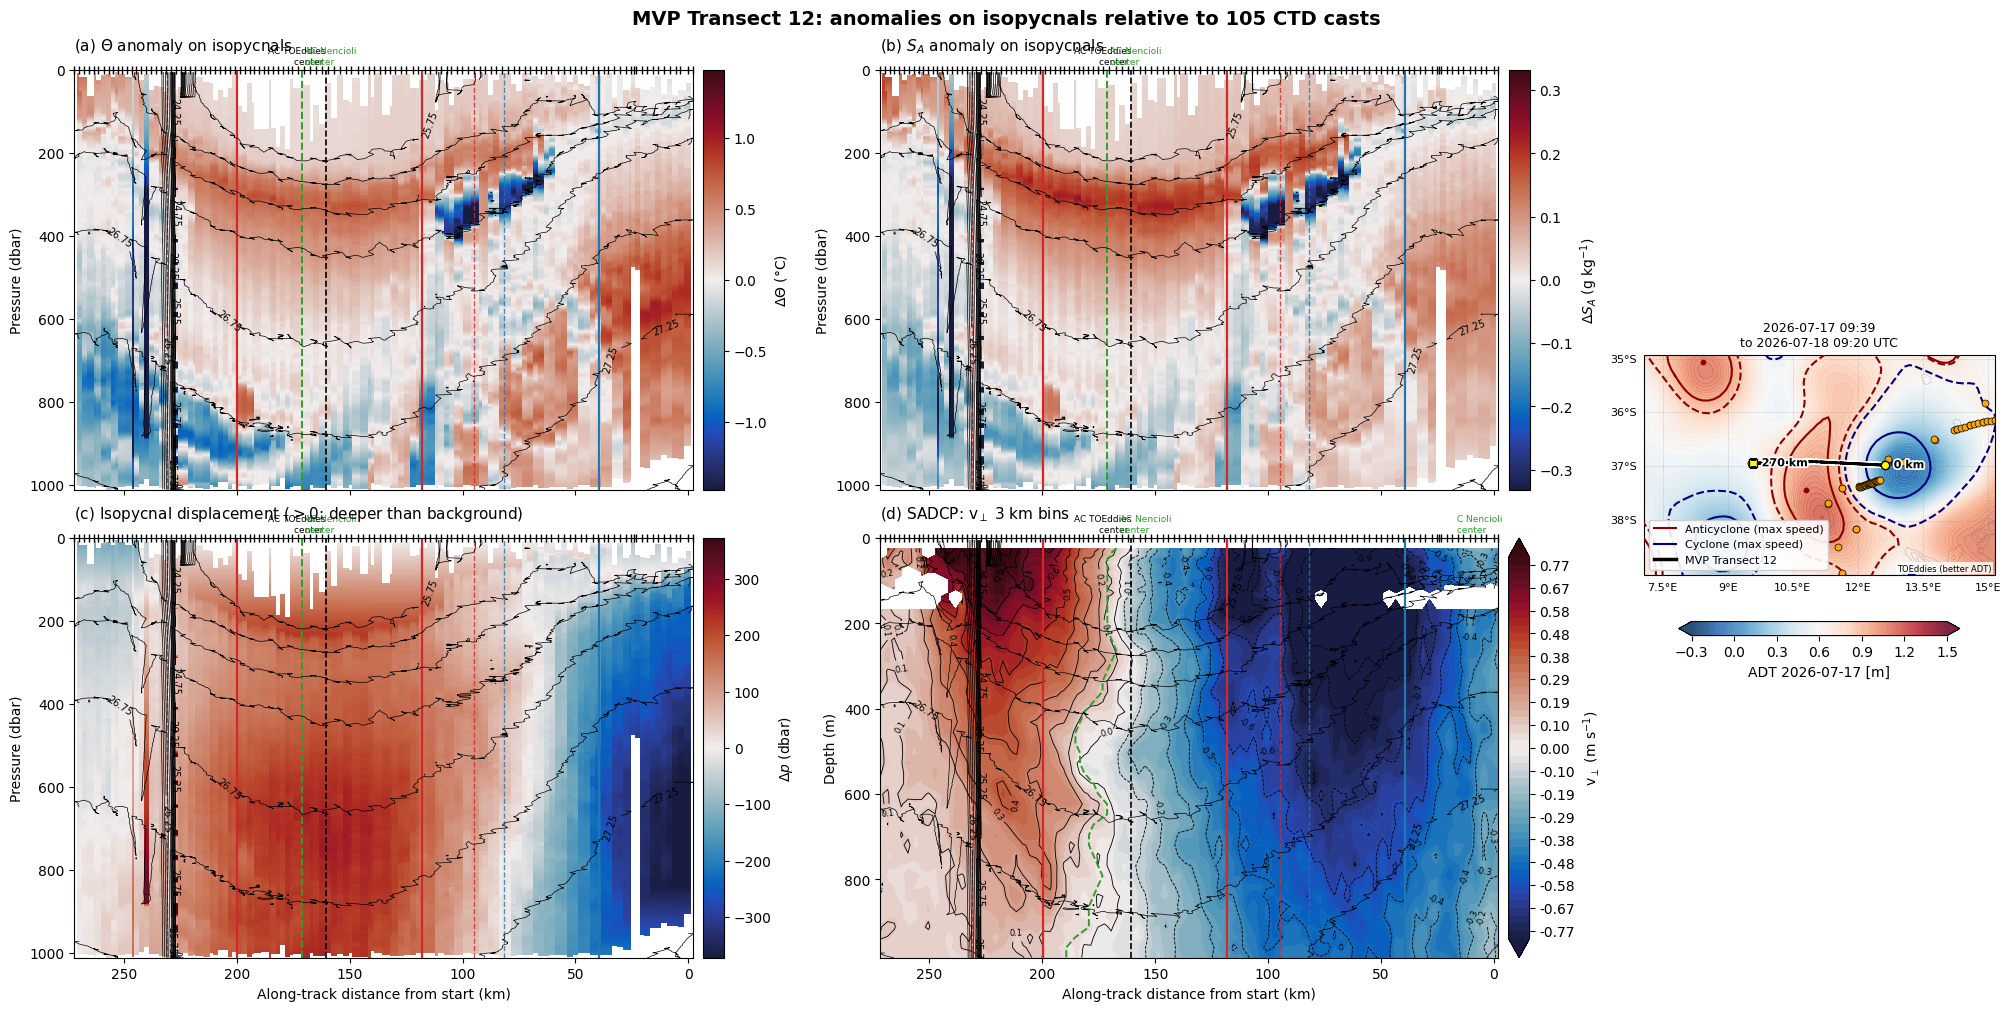

In [40]:
# ---------------- run ----------------
anoms = dict(CT=anom(ctd_ref, sec, "temp"),
             SA=anom(ctd_ref, sec, "sal"),
             disp=anom(ctd_ref, sec, "disp"))
for k, a in anoms.items():
    print(f"{k:5s} anomaly: {np.nanmin(a):+.3f} .. {np.nanmax(a):+.3f}, "
          f"{np.isfinite(a).mean() * 100:.0f}% of the section filled")

fig, axs = plot_anomaly_section_with_map(
    sec, sadcp_mvp_processed, anoms,
    map_draw=draw_background, map_args=args,
    title=f"MVP {transect}: anomalies on isopycnals relative to {len(ref_used)} CTD casts",
    edd=edds, flip_x=invert_x, vel_lim=0.8,
    ref_lon=ref_used["lon"].values, ref_lat=ref_used["lat"].values,
    savepath=out_dir + f"{transect}_section_anomalies_ctdref_adcp")
plt.show()


## Transect 12 vs Transect 13
Both transects with the same steps as above, the same CTD background (`ctd_ref`) and the same colour bars; 
then the maximum anomalies inside the anticyclone (TOEddies outer contour) and their change per day.

In [41]:
# ---------------- Transects 12 and 13: same steps as the cells above, for both ----------------
from matplotlib.path import Path as MplPath

TRANSECTS = ["Transect 12", "Transect 13"]
# TRANSECTS = ["Transect 14"]

# SADCP files: loaded once
sadcp_full = {}
for inst in ["OS150", "OS38"]:
    s = cascade_add_time(xr.open_dataset(SADCP_FILES[inst])).sortby("time")
    sadcp_full[inst] = s.isel(time=~s.indexes["time"].duplicated())


def merged_sadcp(sadcp_tr_all):
    """OS150 above Z_SPLIT + OS38 below, on the same 10-min time axis (as in the SADCP cell)."""
    a = sadcp_window("OS150", sadcp=cascade_to_window_format(sadcp_tr_all["OS150"], pgood_min=50))
    b = sadcp_window("OS38", sadcp=cascade_to_window_format(sadcp_tr_all["OS38"], pgood_min=50))
    t = np.union1d(a["time"], b["time"])

    def on_t(d, key):
        out = np.full((len(t),) + d[key].shape[1:], np.nan)
        out[np.searchsorted(t, d["time"])] = d[key]
        return out

    lon_a, lat_a = on_t(a, "lon"), on_t(a, "lat")
    return dict(time=t,
                lon=np.where(np.isnan(lon_a), on_t(b, "lon"), lon_a),
                lat=np.where(np.isnan(lat_a), on_t(b, "lat"), lat_a),
                z=np.concatenate([a["z"], b["z"]]),
                u=np.concatenate([on_t(a, "u"), on_t(b, "u")], axis=1),
                v=np.concatenate([on_t(a, "v"), on_t(b, "v")], axis=1))


def prepare_transect(transect):
    """MVP section, SADCP, eddies, map background and anomalies of one transect."""
    files = sorted((DIR_MVP / transect).glob("*.csv"))
    dfs = []
    for k, f in enumerate(files):
        df = pd.read_csv(f)
        df["CAST"] = k                       # one processed CSV file = one MVP cast
        dfs.append(df)
    mvp = pd.concat(dfs, ignore_index=True)

    sadcp_tr_all = {inst: sadcp_for_transect(mvp, s) for inst, s in sadcp_full.items()}
    nav = sadcp_on_mvp_times(mvp, sadcp_tr_all["OS150"], max_gap="30min",
                             keep=("LATITUDE", "LONGITUDE"))
    mvp["LON (°E)"] = mvp["LON (°E)"].fillna(pd.Series(nav["LONGITUDE"].values, index=mvp.index))
    mvp["LAT (°N)"] = mvp["LAT (°N)"].fillna(pd.Series(nav["LATITUDE"].values, index=mvp.index))
    adcp = merged_sadcp(sadcp_tr_all)

    date = pd.to_datetime(mvp["TIME"]).median().strftime("%Y-%m-%d")
    date_compact = date.replace("-", "")
    ssh = load_satellite(DIR_SSH / [f for f in daily_ssh_files if date in f or date_compact in f][0])
    eddy_files, eddy_source = get_eddy_files(date_compact, date)
    edds = eddies_on_transect(eddy_files, mvp["LON (°E)"].values, mvp["LAT (°N)"].values)

    # section: the same steps as process_transect, without its figure
    casts = fill_cast_positions(split_by_cast_id(mvp, "CAST"))
    sec = build_section(casts, dp=1.0)
    sec["x"], sec["xdir"] = along_track_x(sec["lon"], sec["lat"])

    invert_x = transect != "Transect 13"     # same convention as the SADCP cell above
    if not invert_x:                         # sign flip on a copy, so re-running is safe
        adcp = dict(adcp, u=-adcp["u"], v=-adcp["v"])

    anoms = dict(CT=anom(ctd_ref, sec, "temp"),
                 SA=anom(ctd_ref, sec, "sal"),
                 disp=anom(ctd_ref, sec, "disp"))
    eddy_txt = [("C" if e["cyc"] else "AC") + f" ({e['dist_km']:.0f} km)" for e in edds]
    print(f"{transect}: {len(files)} casts, {date}, eddies crossed: {eddy_txt}")
    return dict(transect=transect, sec=sec, adcp=adcp, anoms=anoms, edds=edds, date=date,
                invert_x=invert_x,
                args=[ssh, eddy_files, transect, eddy_source, adt_ticks, date, levels])


runs = [prepare_transect(tr) for tr in TRANSECTS]


Calculating Mean
  ! PGOOD_ADCP is all 0 in this file -> PGOOD mask skipped
Calculating Mean
Transect 12: 118 casts, 2026-07-17, eddies crossed: ['C (15 km)', 'AC (58 km)']
Calculating Mean
  ! PGOOD_ADCP is all 0 in this file -> PGOOD mask skipped
Calculating Mean
Transect 13: 60 casts, 2026-07-18, eddies crossed: ['AC (88 km)']


common colour limits: {'CT': 1.195, 'SA': 0.273, 'disp': 361.896} | v: 0.8 m/s
  C: TOEddies center at -16 km, outside section (-2-272 km) -> not marked
  C: Nencioli minimum on the edge of the search box -> no centre


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_16150/3309952731.py:55: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmocean.cm.balance, shading="nearest",


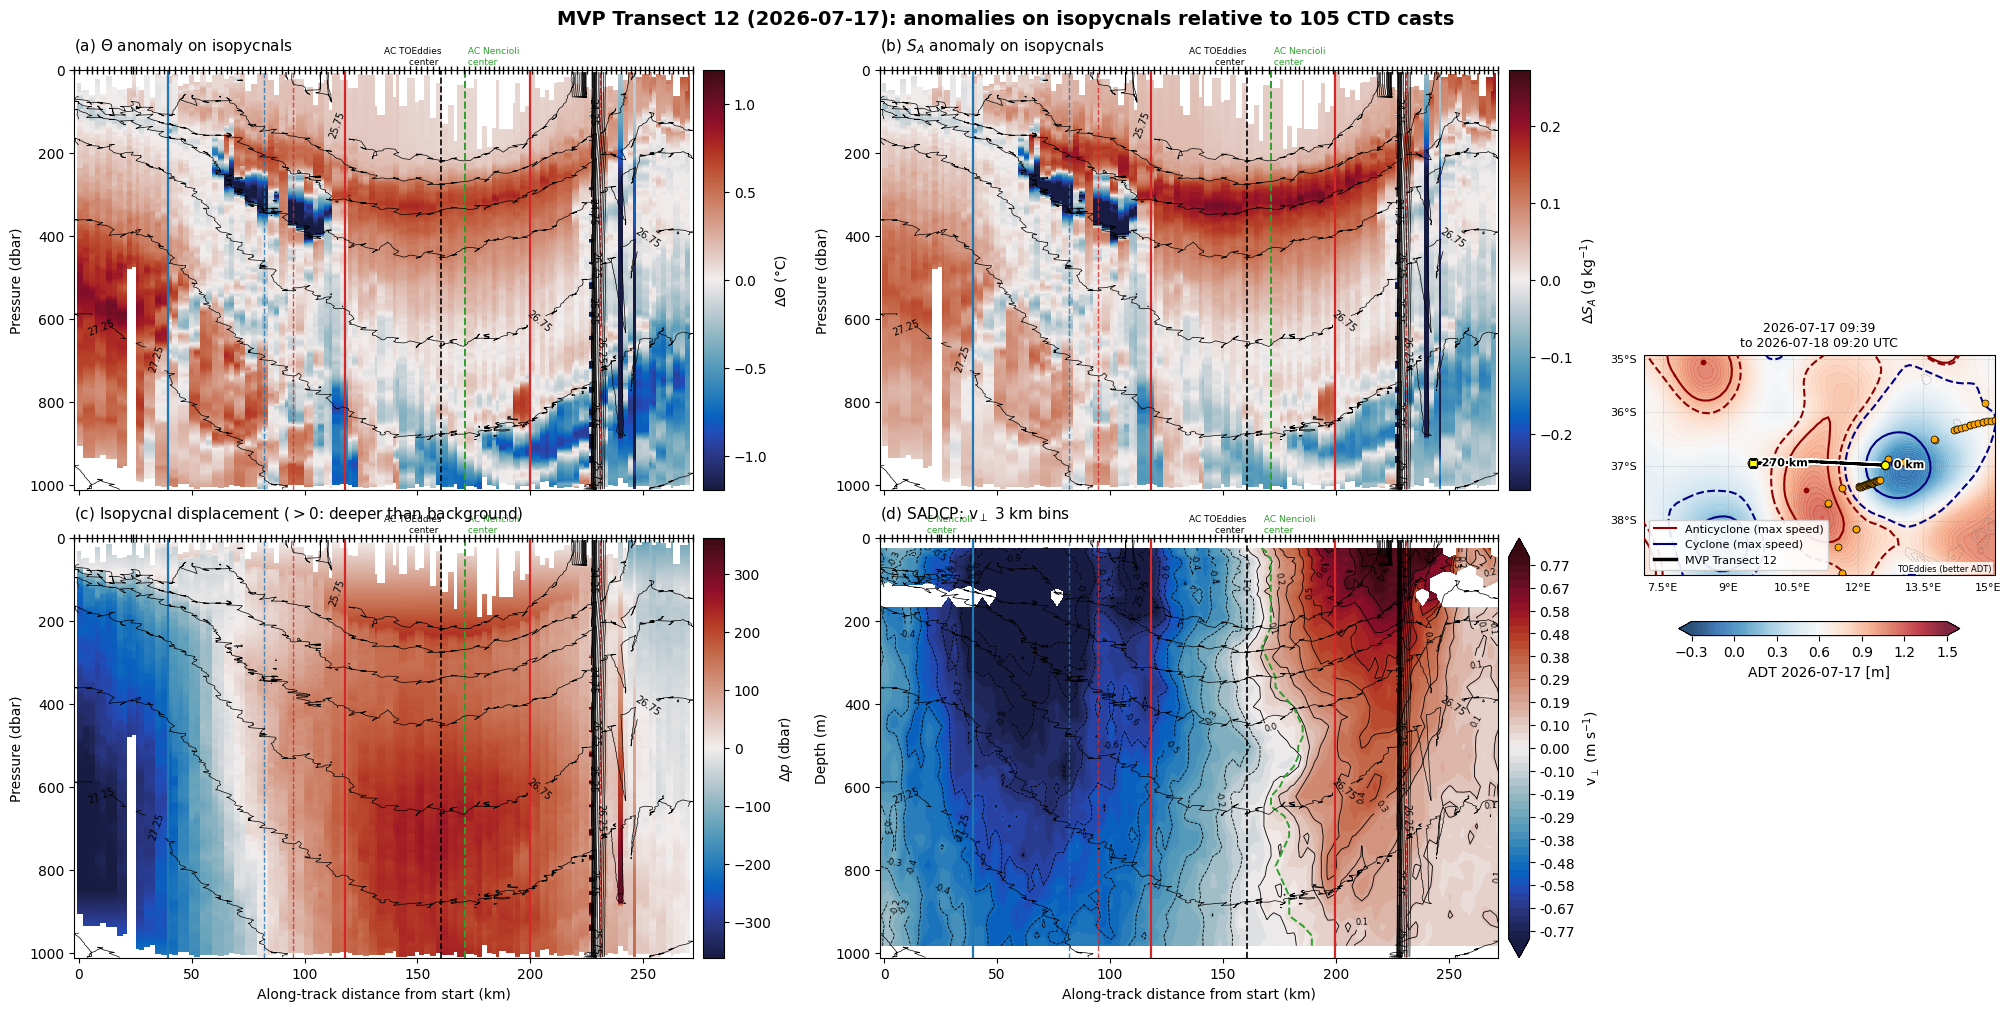

/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_16150/3309952731.py:55: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmocean.cm.balance, shading="nearest",


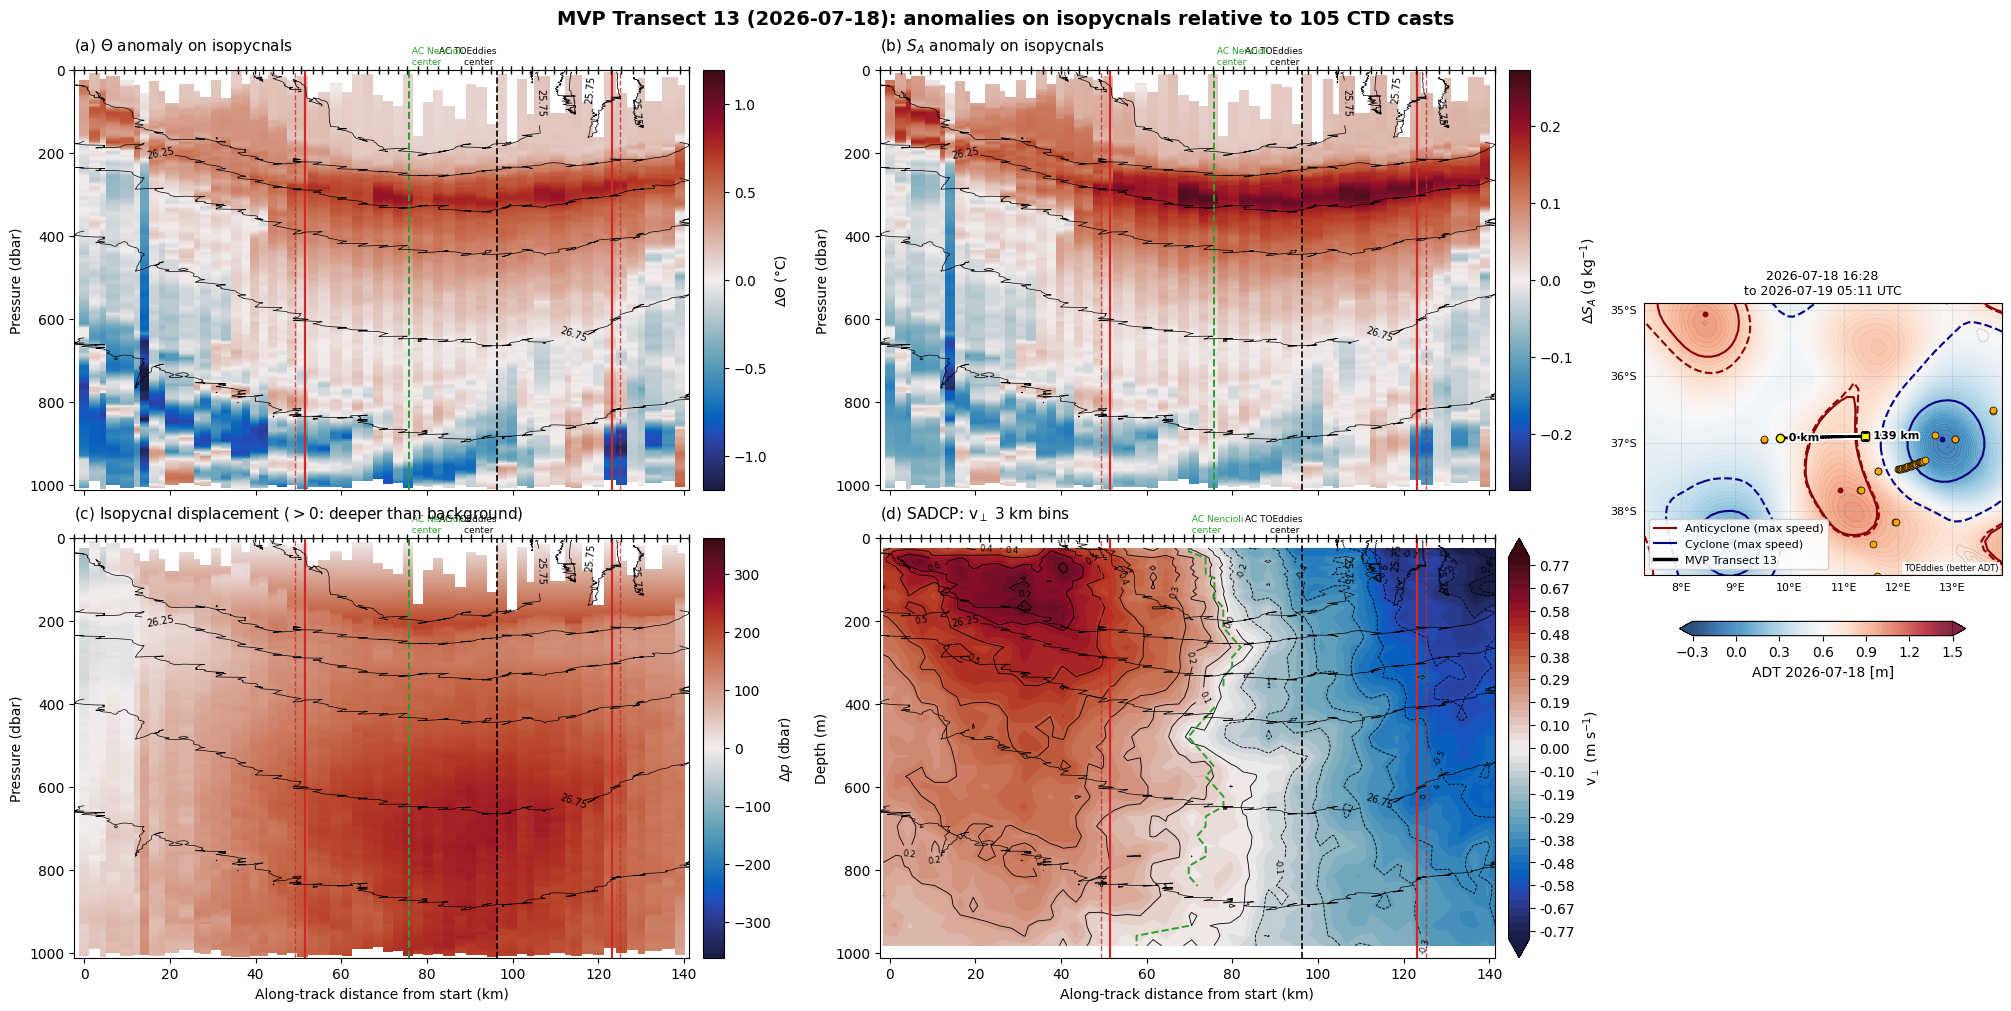

In [42]:
# ---------------- same colour bars on both figures ----------------
def common_limits(runs, pct=99):
    """Symmetric colour limit per anomaly: pct-th percentile of |anomaly| over ALL transects."""
    lims = {}
    for key in ["CT", "SA", "disp"]:
        vals = np.concatenate([np.abs(r["anoms"][key][np.isfinite(r["anoms"][key])]) for r in runs])
        lims[key] = float(np.percentile(vals, pct))
    return lims


anom_lims = common_limits(runs)
sig_all = np.concatenate([r["sec"]["sig0"][np.isfinite(r["sec"]["sig0"])] for r in runs])
sig_levels = np.arange(np.floor(sig_all.min() * 4) / 4, sig_all.max(), 0.25)
pmax = max(np.nanmax(r["sec"]["p"]) for r in runs)
print("common colour limits:", {k: round(v, 3) for k, v in anom_lims.items()}, "| v: 0.8 m/s")

for r in runs:
    out = str(BASE / "figures/mvp" / r["transect"]) + "/"
    os.makedirs(out, exist_ok=True)
    fig, axs = plot_anomaly_section_with_map(
        r["sec"], r["adcp"], r["anoms"],
        map_draw=draw_background, map_args=r["args"],
        title=f"MVP {r['transect']} ({r['date']}): anomalies on isopycnals relative to "
              f"{len(ref_used)} CTD casts",
        edd=r["edds"], flip_x=False, vel_lim=0.8, anom_lims=anom_lims,
        sig_levels=sig_levels, pmax=pmax,
        ref_lon=ref_used["lon"].values, ref_lat=ref_used["lat"].values,
        savepath=out + f"{r['transect']}_section_anomalies_ctdref_adcp_common")
    plt.show()


In [43]:
# ---------------- maximum anomalies in the anticyclone, and change per day ----------------
from matplotlib.path import Path as MplPath

LABELS = {"CT": ("ΔΘ", "°C"), "SA": ("ΔS_A", "g/kg"), "disp": ("Δp", "dbar")}


def anticyclone_casts(r):
    """Casts inside the TOEddies OUTER contour of the anticyclone(s) crossed by the transect."""
    pts = np.c_[r["sec"]["lon"], r["sec"]["lat"]]
    inside = np.zeros(len(pts), bool)
    for e in r["edds"]:
        if not e["cyc"]:
            inside |= MplPath(e["outer"]).contains_points(pts)
    return inside


def eddy_stats(r):
    sec, inside = r["sec"], anticyclone_casts(r)
    if not inside.any():
        print(f"  ! {r['transect']}: no cast inside an anticyclone contour -> whole section used")
        inside[:] = True
    t_mid = pd.DatetimeIndex(sec["time"])[inside].mean()
    rows = []
    for key, (name, unit) in LABELS.items():
        a = np.where(inside[None, :], r["anoms"][key], np.nan)
        if not np.isfinite(a).any():
            continue
        ip, ic = np.unravel_index(np.nanargmax(a), a.shape)
        rows.append(dict(transect=r["transect"], time=t_mid, var=name, unit=unit,
                         max=a[ip, ic], p99=np.nanpercentile(a, 99), min=np.nanmin(a),
                         p_at_max=sec["p"][ip], x_at_max_km=sec["x"][ic] / 1e3,
                         sig0_at_max=sec["sig0"][ip, ic], n_casts=int(inside.sum())))
    return rows


stats = pd.DataFrame([row for r in runs for row in eddy_stats(r)])
pd.set_option("display.float_format", "{:.3f}".format)
print(stats.drop(columns="time").to_string(index=False))

# change between the two transects
a, b = TRANSECTS[0], TRANSECTS[1]
dt_days = (stats.loc[stats.transect == b, "time"].iloc[0]
           - stats.loc[stats.transect == a, "time"].iloc[0]).total_seconds() / 86400
print(f"\n{a} -> {b}: {dt_days:.2f} days between the anticyclone crossings\n")
chg = []
for name, unit in LABELS.values():
    sa = stats[(stats.transect == a) & (stats["var"] == name)]
    sb = stats[(stats.transect == b) & (stats["var"] == name)]
    if sa.empty or sb.empty:
        continue
    for col in ["max", "p99", "sig0_at_max", "p_at_max"]:
        d = sb[col].iloc[0] - sa[col].iloc[0]
        u = {"max": unit, "p99": unit, "sig0_at_max": "kg/m3", "p_at_max": "dbar"}[col]
        chg.append(dict(var=name, quantity=col, **{a: sa[col].iloc[0], b: sb[col].iloc[0]},
                        change=d, per_day=d / dt_days, unit=u))
changes = pd.DataFrame(chg)
print(changes.to_string(index=False))


   transect  var unit     max     p99      min  p_at_max  x_at_max_km  sig0_at_max  n_casts
Transect 12   ΔΘ   °C   1.565   0.696  -12.025  1003.500      229.240       27.461       58
Transect 12 ΔS_A g/kg   0.247   0.202   -2.810   308.500      186.002       26.210       58
Transect 12   Δp dbar 924.405 250.663 -210.939   944.500      229.240       27.175       58
Transect 13   ΔΘ   °C   0.879   0.788   -1.134   298.500       70.858       26.211       30
Transect 13 ΔS_A g/kg   0.258   0.231   -0.177   298.500       70.858       26.211       30
Transect 13   Δp dbar 258.416 249.490    4.461   735.500       92.921       26.823       30

Transect 12 -> Transect 13: 1.03 days between the anticyclone crossings

 var    quantity  Transect 12  Transect 13   change  per_day  unit
  ΔΘ         max        1.565        0.879   -0.686   -0.667    °C
  ΔΘ         p99        0.696        0.788    0.092    0.090    °C
  ΔΘ sig0_at_max       27.461       26.211   -1.250   -1.217 kg/m3
  ΔΘ    p_at_m

## Water masses in the anticyclone (transects 12 and 13)
Definitions of Barabinot et al. (2025, EUREC4A-OA, Sect. 3.4): SMW σ0 < 25.6; SACW σ0 25.6–26.5; 
ESACW Θ 9.44–13.60 °C, S_A 34.90–35.40 g/kg, σ0 26.5–26.93 (Liu and Tanhua 2021); AAIW σ0 ≥ 26.93. 
Indian Ocean Subtropical Mode Waters (mean ± 1 std, converted from θ/psu to Θ/S_A): IOSTMW θ 16.54 ± 0.49 °C, S 35.31 ± 0.04, σθ 26.0 ± 0.1 (25–50°E, 27–38°S); IOSTMW2 θ 12.84 ± 0.57 °C, S 35.17 ± 0.11, σθ 26.57 ± 0.04 (60–80°E, 37–42°S). The mode-water boxes take priority over SACW / ESACW. 
Water in the ESACW density range but outside its Θ–S_A box is split into warmer/saltier (Indian-Ocean-like) 
and colder/fresher. Needs `runs`, `anticyclone_casts`, `ctd_ref`, `interp_on_rho` and `pmax` from the cells above.

In [50]:
# ---------------- water masses (definitions of Barabinot et al. 2025, EUREC4A, Sect. 3.4) ----------------
# SMW:   sigma0 < 25.6 (Memery et al. 2000)
# SACW:  sigma0 25.6-26.5 (Memery et al. 2000; Gordon 1981)
# ESACW: Theta 9.44-13.60 degC, S_A 34.90-35.40 g/kg, sigma0 26.5-26.93 (Liu and Tanhua 2021)
# AAIW:  sigma0 >= 26.9 (Liu and Tanhua 2021)
# IOSTMW, IOSTMW2: Indian Ocean Subtropical Mode Waters (theta/S/sigma boxes, mean +/- 1 std)
# A point that matches none of these definitions is left unclassified (NaN = not coloured).
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches

ESACW = dict(CT=(9.44, 13.60), SA=(34.90, 35.40), sig=(26.5, 26.93))
AAIW_SIG_MIN = 26.9

# Indian Ocean Subtropical Mode Waters, given as mean +/- 1 std in potential temperature (theta),
# practical salinity (psu) and sigma_theta. Converted to Theta / S_A at the centre of each
# formation region so they can be compared with the TEOS-10 sections.
#   IOSTMW  (1960-2004): theta 16.54 +/- 0.49, S 35.31 +/- 0.04, sigma 26.00 +/- 0.10; 25-50E, 27-38S
#   IOSTMW2:             theta 12.84 +/- 0.57, S 35.17 +/- 0.11, sigma 26.57 +/- 0.04; 60-80E, 37-42S
def _mode_water_box(pt, dpt, sp, dsp, sig, dsig, lon, lat):
    SA = gsw.SA_from_SP(np.array([sp - dsp, sp + dsp]), 0, lon, lat)
    CT = gsw.CT_from_pt(SA.mean(), np.array([pt - dpt, pt + dpt]))
    return dict(CT=tuple(CT), SA=tuple(SA), sig=(sig - dsig, sig + dsig))

IOSTMW = _mode_water_box(16.54, 0.49, 35.31, 0.04, 26.00, 0.10, lon=37.5, lat=-32.5)
IOSTMW2 = _mode_water_box(12.84, 0.57, 35.17, 0.11, 26.57, 0.04, lon=70.0, lat=-39.5)
for _n, _b in [("IOSTMW", IOSTMW), ("IOSTMW2", IOSTMW2)]:
    print(f"{_n}: Theta {_b['CT'][0]:.2f}-{_b['CT'][1]:.2f} degC, "
          f"S_A {_b['SA'][0]:.3f}-{_b['SA'][1]:.3f} g/kg, sigma0 {_b['sig'][0]:.2f}-{_b['sig'][1]:.2f}")

# ordered by density; mode waters sit next to the class whose density range contains them
WM_SHORT = ["SMW", "SACW", "IOSTMW", "ESACW", "IOSTMW2", "AAIW"]
WM_LABEL = {
    "SMW":     "SMW\n(σ0 < 25.6)",
    "SACW":    "SACW\n(σ0 25.6–26.5)",
    "IOSTMW":  "IOSTMW\n(θ 16.54±0.49 °C,\nS 35.31±0.04,\nσθ 26.0±0.1)",
    "ESACW":   "ESACW\n(Θ 9.44–13.60 °C,\nS_A 34.90–35.40,\nσ0 26.5–26.93)",
    "IOSTMW2": "IOSTMW2\n(θ 12.84±0.57 °C,\nS 35.17±0.11,\nσθ 26.57±0.04)",
    "AAIW":    "AAIW\n(σ0 ≥ 26.9)",
}
WM_NAMES = [WM_LABEL[k] for k in WM_SHORT]
WM_COLORS = ["#fde68a", "#f59e0b", "#0d9488", "#ea580c", "#2563eb", "#7c3aed"]
WM = {name: k for k, name in enumerate(WM_SHORT)}
wm_cmap = ListedColormap(WM_COLORS)
wm_norm = BoundaryNorm(np.arange(-0.5, len(WM_NAMES)), wm_cmap.N)


def _in_box(box, CT, SA, sig0):
    return ((sig0 >= box["sig"][0]) & (sig0 <= box["sig"][1])
            & (CT >= box["CT"][0]) & (CT <= box["CT"][1])
            & (SA >= box["SA"][0]) & (SA <= box["SA"][1]))


def classify_water_masses(CT, SA, sig0):
    """Index in WM_SHORT where a point fits a definition exactly, NaN otherwise.
    Later assignments win: density classes first, then ESACW, then the (tighter) mode-water boxes."""
    cls = np.full(np.shape(sig0), np.nan)
    in_esacw = _in_box(ESACW, CT, SA, sig0)
    cls[sig0 < 25.6] = WM["SMW"]
    cls[(sig0 >= 25.6) & (sig0 < 26.5)] = WM["SACW"]
    cls[(sig0 >= AAIW_SIG_MIN) & ~in_esacw] = WM["AAIW"]
    cls[in_esacw] = WM["ESACW"]            # ESACW wins in the 26.9-26.93 overlap
    cls[_in_box(IOSTMW, CT, SA, sig0)] = WM["IOSTMW"]    # inside the SACW density range
    cls[_in_box(IOSTMW2, CT, SA, sig0)] = WM["IOSTMW2"]  # inside the ESACW range
    cls[~(np.isfinite(CT) & np.isfinite(SA) & np.isfinite(sig0))] = np.nan
    return cls


for r in runs:
    r["wm"] = classify_water_masses(r["sec"]["CT"], r["sec"]["SA"], r["sec"]["sig0"])
    r["in_ac"] = anticyclone_casts(r)

# share of each water mass inside / outside the anticyclone (grid points with data, 0-pmax dbar)
rows = []
for r in runs:
    valid = (np.isfinite(r["sec"]["CT"]) & np.isfinite(r["sec"]["SA"])
             & np.isfinite(r["sec"]["sig0"]))
    for where, m in [("inside AC", r["in_ac"]), ("outside AC", ~r["in_ac"])]:
        w, v = r["wm"][:, m], valid[:, m]
        n = v.sum()
        if n == 0:
            continue
        rows.append({"transect": r["transect"], "where": where, "casts": int(m.sum()),
                     **{name: 100 * np.sum(w == k) / n for k, name in enumerate(WM_SHORT)},
                     "unclassified": 100 * np.sum(v & np.isnan(w)) / n})
wm_table = pd.DataFrame(rows)
pd.set_option("display.float_format", "{:.1f}".format)
print("percentage of the section (grid points with data) in each water mass:")
print(wm_table.to_string(index=False))

IOSTMW: Theta 16.03-17.01 degC, S_A 35.437-35.517 g/kg, sigma0 25.90-26.10
IOSTMW2: Theta 12.26-13.40 degC, S_A 35.226-35.447 g/kg, sigma0 26.53-26.61
percentage of the section (grid points with data) in each water mass:
   transect      where  casts  SMW  SACW  IOSTMW  ESACW  IOSTMW2  AAIW  unclassified
Transect 12  inside AC     58  1.8  39.1     0.0   20.8      5.5  26.0           6.8
Transect 12 outside AC     60  0.0  21.0     0.0   17.6      2.5  52.1           6.8
Transect 13  inside AC     30  0.0  42.0     0.0   21.2      6.4  23.7           6.7
Transect 13 outside AC     30  0.0  31.7     0.0   20.6      4.4  35.3           8.0


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_16150/3691487609.py:11: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, sec["p"], r["wm"], cmap=wm_cmap, norm=wm_norm, shading="nearest")
/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_16150/3691487609.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs_wm[0].legend(loc="lower left", fontsize=8)


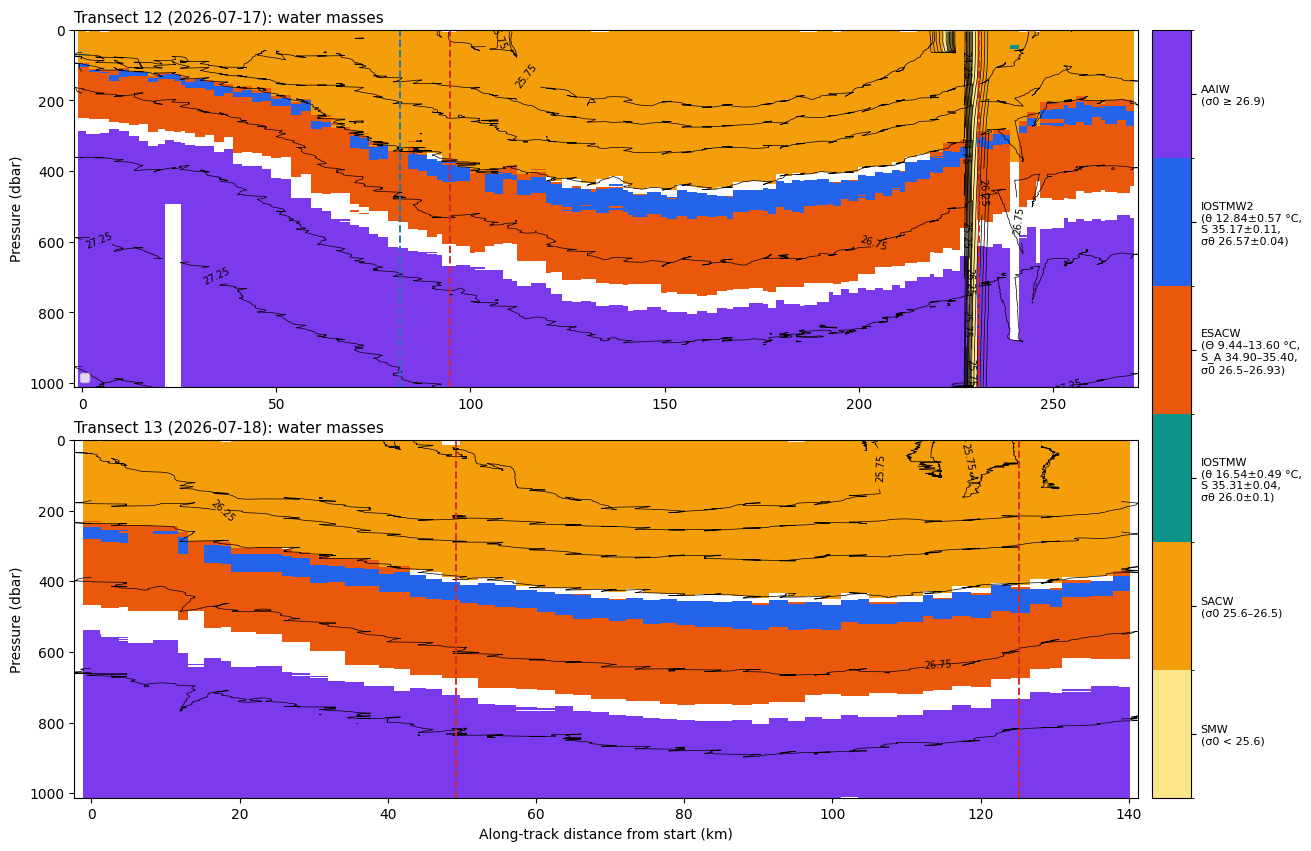

In [51]:
# ---------------- water masses on the sections ----------------
fig, axs_wm = plt.subplots(len(runs), 1, figsize=(13, 4.2 * len(runs)), sharey=True,
                           constrained_layout=True)
axs_wm = np.atleast_1d(axs_wm)
sig_all = np.concatenate([r["sec"]["sig0"][np.isfinite(r["sec"]["sig0"])] for r in runs])
sig_levels = np.arange(np.floor(sig_all.min() * 4) / 4, sig_all.max(), 0.25)
pmax = max(np.nanmax(r["sec"]["p"]) for r in runs)
for ax, r in zip(axs_wm, runs):
    sec = r["sec"]
    xkm = sec["x"] / 1e3
    pc = ax.pcolormesh(xkm, sec["p"], r["wm"], cmap=wm_cmap, norm=wm_norm, shading="nearest")
    cs = ax.contour(xkm, sec["p"], sec["sig0"], levels=sig_levels, colors="k", linewidths=0.5)
    ax.clabel(cs, cs.levels[::2], fontsize=7, fmt="%.2f")
    # anticyclone outer contour (TOEddies) crossing the section
    to_sn = make_to_sn(sec)
    for e in r["edds"]:
        col = "tab:blue" if e["cyc"] else "tab:red"
        for xv in crossings_on_line(e["outer"], to_sn):
            ax.axvline(xv, color=col, ls="--", lw=1.4)
    # ax.plot(xkm[r["in_ac"]], np.zeros(r["in_ac"].sum()), "v", color="tab:red", ms=4,
    #         clip_on=False, label="cast inside AC outer contour")
    ax.set_ylim(pmax, 0)
    ax.set_xlim(np.nanmin(xkm), np.nanmax(xkm))
    # if r["invert_x"]:
    #     ax.invert_xaxis()
    ax.set_ylabel("Pressure (dbar)")
    ax.set_title(f"{r['transect']} ({r['date']}): water masses", loc="left", fontsize=11)
axs_wm[-1].set_xlabel("Along-track distance from start (km)")
cb = fig.colorbar(pc, ax=axs_wm, ticks=range(len(WM_NAMES)), pad=0.01)
cb.ax.set_yticklabels(WM_NAMES, fontsize=8)
axs_wm[0].legend(loc="lower left", fontsize=8)
fig.savefig(str(BASE / "figures/mvp") + "/water_masses_T12_T13.png", dpi=300, bbox_inches="tight")
plt.show()


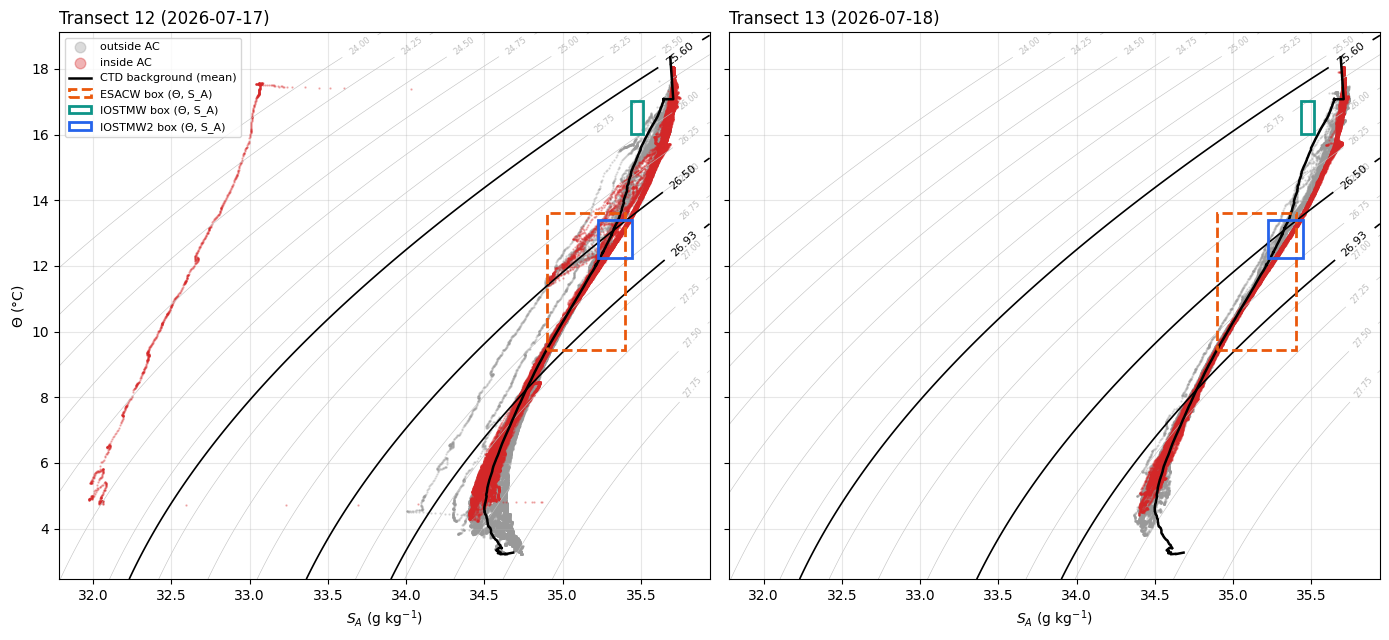

In [49]:
# ---------------- Theta-S: inside vs outside the anticyclone ----------------
fig, axs_ts = plt.subplots(1, len(runs), figsize=(7 * len(runs), 6.5), sharex=True, sharey=True)
axs_ts = np.atleast_1d(axs_ts)
for ax, r in zip(axs_ts, runs):
    sec = r["sec"]
    for m, col, lab, z in [(~r["in_ac"], "0.6", "outside AC", 1), (r["in_ac"], "tab:red", "inside AC", 2)]:
        ax.scatter(sec["SA"][:, m].ravel(), sec["CT"][:, m].ravel(), s=0.4, color=col,
                   alpha=0.35, label=lab, zorder=z, rasterized=True)
    ax.plot(ctd_ref["SA"], ctd_ref["CT"], "k", lw=1.8, label="CTD background (mean)", zorder=3)
    ax.add_patch(mpatches.Rectangle((ESACW["SA"][0], ESACW["CT"][0]),
                                    ESACW["SA"][1] - ESACW["SA"][0], ESACW["CT"][1] - ESACW["CT"][0],
                                    fill=False, ec="#ea580c", lw=2, ls="--", zorder=4,
                                    label="ESACW box (Θ, S_A)"))
    for name, box, col in [("IOSTMW", IOSTMW, "#0d9488"), ("IOSTMW2", IOSTMW2, "#2563eb")]:
        ax.add_patch(mpatches.Rectangle((box["SA"][0], box["CT"][0]),
                                        box["SA"][1] - box["SA"][0], box["CT"][1] - box["CT"][0],
                                        fill=False, ec=col, lw=2, ls="-", zorder=4,
                                        label=f"{name} box (Θ, S_A)"))
    ax.set_title(f"{r['transect']} ({r['date']})", loc="left")
    ax.set_xlabel(r"$S_A$ (g kg$^{-1}$)")
    ax.grid(alpha=0.3)
axs_ts[0].set_ylabel(r"$\Theta$ (°C)")
for ax in axs_ts:
    SAg, CTg = np.meshgrid(np.linspace(*ax.get_xlim(), 200), np.linspace(*ax.get_ylim(), 200))
    sg = gsw.sigma0(SAg, CTg)
    cs = ax.contour(SAg, CTg, sg, levels=np.arange(24, 28, 0.25), colors="0.75", linewidths=0.4)
    ax.clabel(cs, fmt="%.2f", fontsize=6)
    cs = ax.contour(SAg, CTg, sg, levels=[25.6, 26.5, 26.93], colors="k", linewidths=1.2)
    ax.clabel(cs, fmt="%.2f", fontsize=8)
axs_ts[0].legend(loc="upper left", fontsize=8, markerscale=12)
plt.tight_layout()
plt.show()


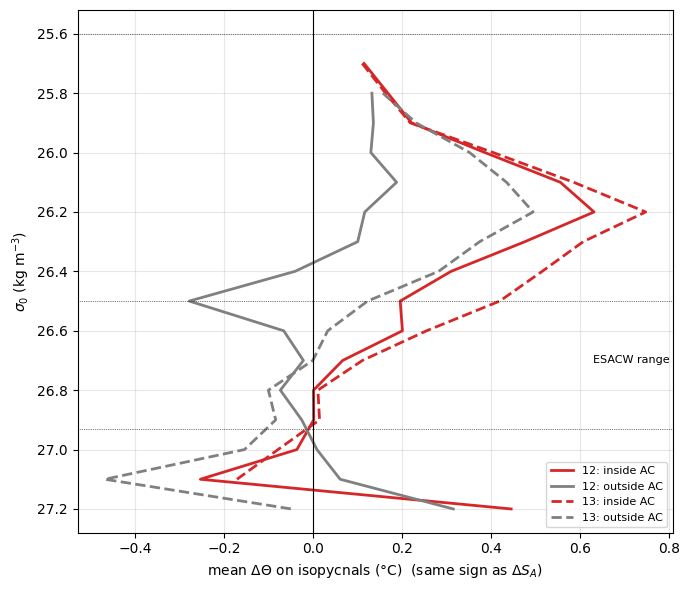

In [34]:
# ---------------- spiciness on isopycnals: is the core water "Indian" (warmer AND saltier)? ----------------
# Along an isopycnal, Theta and S_A anomalies have the same sign (density-compensated):
# positive = warmer and saltier = more Indian-Ocean-like; negative = colder and fresher.
rho_levels = np.round(np.arange(25.6, 27.21, 0.1), 2)
fig, ax = plt.subplots(figsize=(7, 6))
for r, ls in zip(runs, ["-", "--"]):
    sec = r["sec"]
    for m, col, lab in [(r["in_ac"], "tab:red", "inside AC"), (~r["in_ac"], "0.5", "outside AC")]:
        if not m.any():
            continue
        dct = np.array([interp_on_rho(sec["sig0"][:, i], r["anoms"]["CT"][:, i], rho_levels)
                        for i in np.flatnonzero(m)])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            ax.plot(np.nanmean(dct, axis=0), rho_levels, ls, color=col, lw=2,
                    label=f"{r['transect'].split()[-1]}: {lab}")
ax.axvline(0, color="k", lw=0.8)
for y in [25.6, 26.5, 26.93]:
    ax.axhline(y, color="k", lw=0.5, ls=":")
ax.text(ax.get_xlim()[1], 26.7, "ESACW range ", ha="right", va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlabel(r"mean $\Delta\Theta$ on isopycnals (°C)  (same sign as $\Delta S_A$)")
ax.set_ylabel(r"$\sigma_0$ (kg m$^{-3}$)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
